<a href="https://colab.research.google.com/github/soumyakumbar06/Machine-Learning-Lab-Exp/blob/main/LR_vs_PR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter 9 X values: 1 2 3 4 5 6 7 8 9
Enter 9 Y values: 1 4 9 16 25 36 49 64 81

----- MSE COMPARISON -----

Linear Regression
Training MSE: 2.8000
Validation MSE: 122.5000
Testing MSE: 842.5000

Polynomial Regression (Degree 2)
Training MSE: 0.0000
Validation MSE: 0.0000
Testing MSE: 0.0000


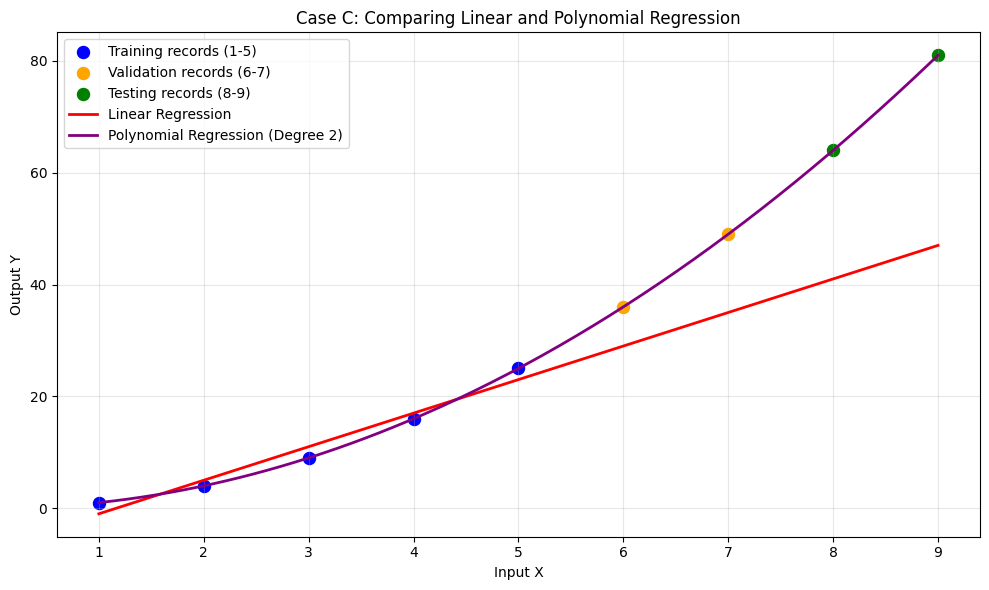

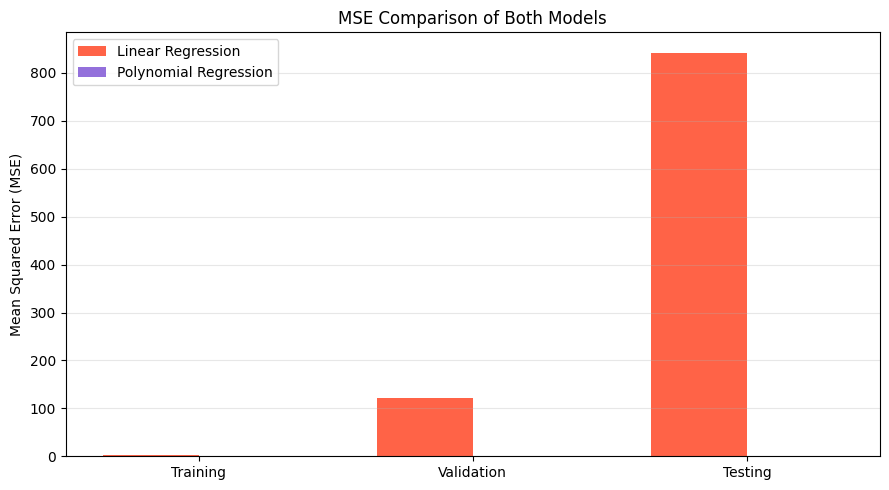


----- FINAL RECOMMENDATION -----
Polynomial Regression has lower validation MSE.
It is the preferred model based on validation performance.

Use the test MSE to report final performance.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

X = np.array(list(map(float, input("Enter 9 X values: ").split()))).reshape(-1, 1)
Y = np.array(list(map(float, input("Enter 9 Y values: ").split())))

if len(X) != 9 or len(Y) != 9:
    raise ValueError("Please enter exactly 9 X values and 9 Y values.")

X_train, y_train = X[:5], Y[:5]    # Records 1-5
X_val, y_val = X[5:7], Y[5:7]      # Records 6-7
X_test, y_test = X[7:9], Y[7:9]    # Records 8-9

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)
poly_model.fit(X_train, y_train)
splits = [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]

print("\n----- MSE COMPARISON -----")
results = {}
for name, model in [
    ("Linear Regression", linear_model),
    ("Polynomial Regression (Degree 2)", poly_model)
]:
    results[name] = []
    print(f"\n{name}")

    for split_name, x_data, y_data in splits:
        predictions = model.predict(x_data)
        mse = mean_squared_error(y_data, predictions)
        results[name].append(mse)
        print(f"{split_name} MSE: {mse:.4f}")

x_curve = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_train, Y[:5], color="blue", s=75,
            label="Training records (1-5)")
plt.scatter(X_val, Y[5:7], color="orange", s=75,
            label="Validation records (6-7)")
plt.scatter(X_test, Y[7:9], color="green", s=75,
            label="Testing records (8-9)")
plt.plot(x_curve, linear_model.predict(x_curve),
         color="red", linewidth=2,
         label="Linear Regression")
plt.plot(x_curve, poly_model.predict(x_curve),
         color="purple", linewidth=2,
         label="Polynomial Regression (Degree 2)")
plt.xlabel("Input X")
plt.ylabel("Output Y")
plt.title("Case C: Comparing Linear and Polynomial Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

labels = ["Training", "Validation", "Testing"]
x_pos = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x_pos - width / 2, results["Linear Regression"],
        width, label="Linear Regression", color="tomato")
plt.bar(x_pos + width / 2,
        results["Polynomial Regression (Degree 2)"],
        width, label="Polynomial Regression", color="mediumpurple")
plt.xticks(x_pos, labels)
plt.ylabel("Mean Squared Error (MSE)")
plt.title("MSE Comparison of Both Models")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

linear_avg = np.mean(results["Linear Regression"])
poly_avg = np.mean(results["Polynomial Regression (Degree 2)"])

print("\n----- FINAL RECOMMENDATION -----")

if results["Polynomial Regression (Degree 2)"][1] < results["Linear Regression"][1]:
    print("Polynomial Regression has lower validation MSE.")
    print("It is the preferred model based on validation performance.")
elif results["Polynomial Regression (Degree 2)"][1] > results["Linear Regression"][1]:
    print("Linear Regression has lower validation MSE.")
    print("It is the preferred model based on validation performance.")
else:
    print("Both models have equal validation MSE.")
    print("Use other considerations to select the model.")

print("\nUse the test MSE to report final performance.")